In [18]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

In [19]:
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split

In [20]:
X, y = make_moons(n_samples=1000, noise=0.25, random_state=42)

In [21]:
X.shape

(1000, 2)

In [22]:
y.shape

(1000,)

In [23]:
# Split the data

# X contains the input features
# y contains the correct class labels
# X_train, y_train are used to teach the neural network
# X_test, y_test are kept separate to check whether the model learned patterns that work on unseen examples
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

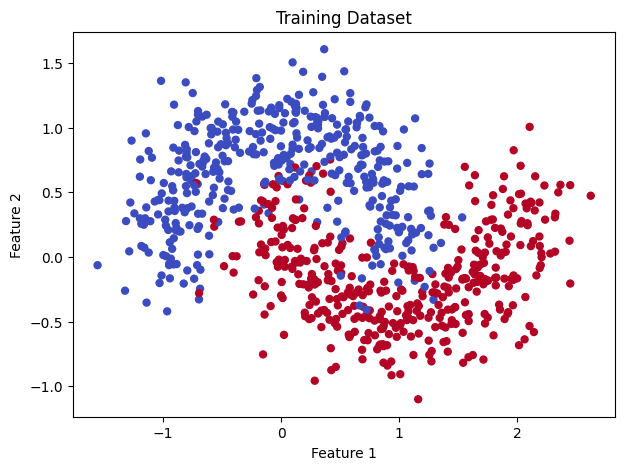

In [24]:
# Visualize the data
plt.figure(figsize=(7, 5))
plt.scatter(X_train[:, 0], X_train[:, 1], c=y_train, cmap="coolwarm", s=25)
plt.title("Training Dataset")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()

In [25]:
print(f"Training examples: {len(X_train)}")
print(f"Testing examples: {len(X_test)}")

Training examples: 800
Testing examples: 200


# Build an MLP with enough capacity to momorize

In [26]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input

# This tells keras what the neural network looks like
model = Sequential(
    [
        Input(shape=(2,)),
        Dense(128, activation="relu"),
        Dense(128, activation="relu"),
        Dense(128, activation="relu"),
        Dense(1, activation="sigmoid")
    ]
)
# Input layer --> 2 features
# Hidden layer 1 --> 128 neurons - ReLU
# Hidden layer 2 --> 128 neurons - ReLU
# Hidden layer 3 --> 128 neurons - ReLU
# Output layer --> 1 neuron - sigmoid


In [27]:
# This configures how my Neural Network will learn, how it will measure mistakes, and how we will track its performance during training

# model.compile --> Preparing the model for training. It configures the training process by specifying the optimizer, the loss function, and the metrics.
# It does not train the model itself
model.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])

In [28]:
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_4 (Dense)                 │ (None, 128)            │           384 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 33,537 (131.00 KB)

 Trainable params: 33,537 (131.00 KB)

 Non-trainable params: 0 (0.00 B)

### The key experiment: Give the network random labels

In [34]:
# Normally, each training example has a meaningful label. Instead, we will shuffle the training labels randomly while leaving the test labels unchanged. This means the model is being asked to learn a relationship that doesn't actually exist in the training labels

# Make the experiment reproducible - This sets up a random number generator
rng = np.random.default_rng(42)

# Shuffling the training labels. Technically, rng.permutation(y_train) returns a shuffled copy of the array, it does not change y_train itself
y_train_random = rng.permutation(y_train)


# Train the MLP on random labels

# model.fit() --> This starts the training process. THe model makes predictions, calculates the loss, computes gradients through backpropagation, and updates its weights using the Adam Optimizer
# X_train -- These are the training inputs - the features the model receives
# y_train_random --> These are the labels the model must learn to predict. We are deliberately using shuffled labels
# epochs = 150
# batch_size = 32 --> The model processes up to 32 training examples in each batch before making an optimizer update.
# validation_data(X_test, y_test) --> We train using X_train, y_train_random, but we validate using X_test, y_test. The test labels are the original, correct labels, not the randomized ones
# verbose --> This controls the amount of progress information Keras prints

# History --> The result of model.fit() is stored in the history variable. It contains the loss and metrics recorded during training including validation results
history = model.fit(
    X_train,
    y_train_random,
    epochs=150,
    batch_size=32,
    validation_data=(X_test, y_test),
    verbose=0)


print("Training on random labels completed")


# Originally the training labels represented the actual classes of the moon-shaped dataset. We replaced them with randomly rearranged labels. For example, an input that originally belonged to class 0 might now have label 1, and vice versa. The neural network doesn't know we randomized the labels. It simply tries to minimize its training loss

Training on random labels completed


In [35]:
history.history.keys()

dict_keys(['accuracy', 'loss', 'val_accuracy', 'val_loss'])

In [30]:
print(f"Original Labels: {y_train[:10]}")
print(f"Shuffled labels: {y_train_random[:10]}")

Original Labels: [1 0 0 0 1 0 1 1 0 0]
Shuffled labels: [0 0 1 1 0 1 1 1 0 0]


## Check whether the network memorized

In [31]:
# These 2 lines are used to evaluate the trained NN on two different datasets.They're especially important in our MLP memorization experiment because they help us determine whether the model has memorized the training labels or learned something that generalizes.

# Evaluate on the training data. Here, we're evaluating the model using the same inputs and randomized labels it was trained on.
# train_loss --> the BCE loss on the training data
# train_accuracy --> the fraction of predictions that match the randomized training labels.
train_loss, train_accuracy = model.evaluate(X_train, y_train_random, verbose=0)

# We use test inputs and their original labels
test_loss, test_accuracy = model.evaluate(X_test, y_test, verbose=0)

In [36]:
print(f"Train Loss: {train_loss}")
print(f"Train Accuracy: {train_accuracy}")

Train Loss: 0.626227617263794
Train Accuracy: 0.6287500262260437


In [37]:
print(f"test Loss: {test_loss}")
print(f"test Accuracy: {test_accuracy}")

test Loss: 0.8445431590080261
test Accuracy: 0.375


In [38]:
print(f"Training accuracy on random labels: {train_accuracy:.2%}")
print(f"Test accuracy on original labels:   {test_accuracy:.2%}")

Training accuracy on random labels: 62.88%
Test accuracy on original labels:   37.50%


### Why is this memorization?
The model is doing well on the examples it was trained on, even though their labels are random. But it cannot reliably predict the true classes of unseen examples.
That tells us the network has learned to fit the training assignments rather than discovering a useful relationship between the inputs and the actual classes.

## Visualize the training and validation losses

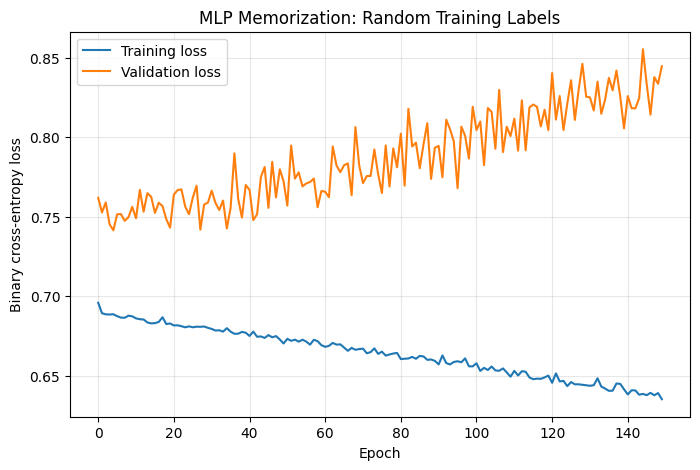

In [33]:
plt.figure(figsize=(8, 5))

plt.plot(history.history["loss"], label="Training loss")
plt.plot(history.history["val_loss"], label="Validation loss")

plt.xlabel("Epoch")
plt.ylabel("Binary cross-entropy loss")
plt.title("MLP Memorization: Random Training Labels")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()